# ACA aimpoint drift validation — 2026:161 jump step

Validates the new drift model (with the `2026:161` jump) by loading it from a local
`chandra_models` branch and comparing corrected aimpoint chip positions against the
current flight model.  No fitting is done here — this is pure validation.

**Method** (from `fit_aimpoint_drift-2025-03`):
- Set `CHANDRA_MODELS_REPO_DIR` / `CHANDRA_MODELS_DEFAULT_VERSION` to point at the
  branch containing the new model.
- For each observation, call `drift.get_aca_offsets()` twice: once with the current
  flight parameters (explicit `drift_pars`), and once using the branch model (via the
  `chandra_models` LazyDict, now pointing at the branch).
- Convert the per-observation DY/DZ correction delta into corrected CHIPX/CHIPY
  positions using the `ASOL_TO_CHIP` matrix transform.
- Plot side-by-side: flight model vs new model.  After `2026:161` the new model
  residuals should be flatter.

In [1]:
import json
import os
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table
from chandra_aca import drift
from cxotime import CxoTime
from ska_helpers import chandra_models
from ska_matplotlib import plot_cxctime

%matplotlib inline

DEPLOY_JUMP_DATE = "2026:161"
SIM_MM_TO_ARCSEC = 20.493
jump_plot_date = CxoTime(DEPLOY_JUMP_DATE).plot_date

## Load flight model and configure branch

Load the current flight model parameters **before** setting the env vars so that the
`chandra_models` `LazyDict` (`drift.DRIFT_PARS`) is still uninitialised and will pick
up the branch model when first accessed.

In [2]:
# Load current flight model pars from released chandra_models
_txt_flight, _info_flight = chandra_models.get_data(
    "chandra_models/aca_drift/aca_drift_model.json"
)
flight_pars = json.loads(_txt_flight)
print(f"Current flight model version: {_info_flight['version']}")

# Now point chandra_models at the branch with the new 2026:161 jump.
# drift.DRIFT_PARS has NOT been accessed yet, so it will load from the branch
# the first time get_aca_offsets() is called without an explicit drift_pars kwarg.
os.environ["CHANDRA_MODELS_REPO_DIR"] = os.path.expanduser("~/git/chandra_models")
os.environ["CHANDRA_MODELS_DEFAULT_VERSION"] = "aimpoint-drift-update-2026"

Current flight model version: 3.74.1


In [3]:
# Verify the new model from the branch
_txt_new, _info_new = chandra_models.get_data(
    "chandra_models/aca_drift/aca_drift_model.json"
)
new_pars = json.loads(_txt_new)
print(f"New model version (branch): {_info_new['version']}")
pprint(new_pars)

New model version (branch): aimpoint-drift-update-2026
{'dy': {'jumps': [['2015:006', -4.6],
                  ['2015:265', -4.669],
                  ['2016:064', -1.793],
                  ['2017:066', -1.725],
                  ['2018:285', -12.505],
                  ['2022:294', -7.966],
                  ['2023:048', -3.5379],
                  ['2024:001', 0.6935],
                  ['2026:161', 1.409]],
        'offset': -6.012,
        'scale': 2.1467,
        'trend': -1.108,
        'year0': 2016.0},
 'dz': {'jumps': [['2015:006', -2.109],
                  ['2015:265', -0.368],
                  ['2016:064', -0.902],
                  ['2017:066', -0.856],
                  ['2018:285', -6.056],
                  ['2022:294', -1.5133],
                  ['2023:048', -1.7357],
                  ['2024:001', 0.3968],
                  ['2026:161', 0.4703]],
        'offset': -15.963,
        'scale': 1.004,
        'trend': -0.159,
        'year0': 2016.0}}


## Load observed aimpoints

In [4]:
aim_obs = Table.read(
    f"{os.environ['SKA']}/data/aimpoint_mon3/observed_aimpoints.dat",
    format="ascii.ecsv",
)

LOOKBACK_START = "2022:001"
ok = (
    (aim_obs["mean_date"] >= LOOKBACK_START)
    & np.isfinite(aim_obs["mean_t_ccd"])
    & (np.abs(aim_obs["target_offset_y"]) < 100)
    & (np.abs(aim_obs["target_offset_z"]) < 100)
)
obs = aim_obs[ok].copy()
print(f"{len(obs)} observations from {LOOKBACK_START} to {obs['mean_date'][-1]}")

5792 observations from 2022:001 to 2026:181:20:47:26.816


## Compute corrected chip positions

For each observation compute the corrected CHIPX/CHIPY that would have been observed
if the flight or new drift model had been applied during planning.  Uses the full
`ASOL_TO_CHIP` matrix transform.

- `drift.get_aca_offsets(..., drift_pars=flight_pars)` — current flight model
- `drift.get_aca_offsets(...)` — new model via `drift.DRIFT_PARS` (branch)

In [5]:
for col in ("dx_corr_flight", "dy_corr_flight", "dx_corr_new", "dy_corr_new"):
    obs[col] = np.nan

for row in obs:
    det = row["detector"]
    chip_id = row["chip_id"]

    try:
        entry = drift.ASOL_TO_CHIP[(det, chip_id)]
    except KeyError:
        continue

    common = {
        "chip_id": chip_id,
        "chipx": row["chipx"],
        "chipy": row["chipy"],
        "time": row["mean_date"],
        "t_ccd": row["mean_t_ccd"],  # degC from observed_aimpoints.dat
    }

    # Flight model — explicit drift_pars bypasses LazyDict
    offsets_flight = drift.get_aca_offsets(det, drift_pars=flight_pars, **common)
    # New model — no drift_pars, so DRIFT_PARS LazyDict loads from branch
    offsets_new = drift.get_aca_offsets(det, **common)

    cyz = np.array(entry["cyz"])
    cyz_inv = np.linalg.inv(cyz)
    arcsec_per_pix = 0.1318 if "HRC" in det else 0.492

    for offsets, dx_col, dy_col in [
        (offsets_flight, "dx_corr_flight", "dy_corr_flight"),
        (offsets_new, "dx_corr_new", "dy_corr_new"),
    ]:
        ddy = row["aca_offset_y"] - offsets[0]
        ddz = row["aca_offset_z"] - offsets[1]
        landing_asol = (
            cyz_inv @ np.array([row["dx"], row["dy"]])
            / arcsec_per_pix
            * SIM_MM_TO_ARCSEC
        )
        total_asol = np.array([ddy, ddz]) + landing_asol
        chip_corr = cyz @ total_asol / SIM_MM_TO_ARCSEC * arcsec_per_pix
        row[dx_col] = chip_corr[0]
        row[dy_col] = chip_corr[1]

## Comparison 90 days around the jump

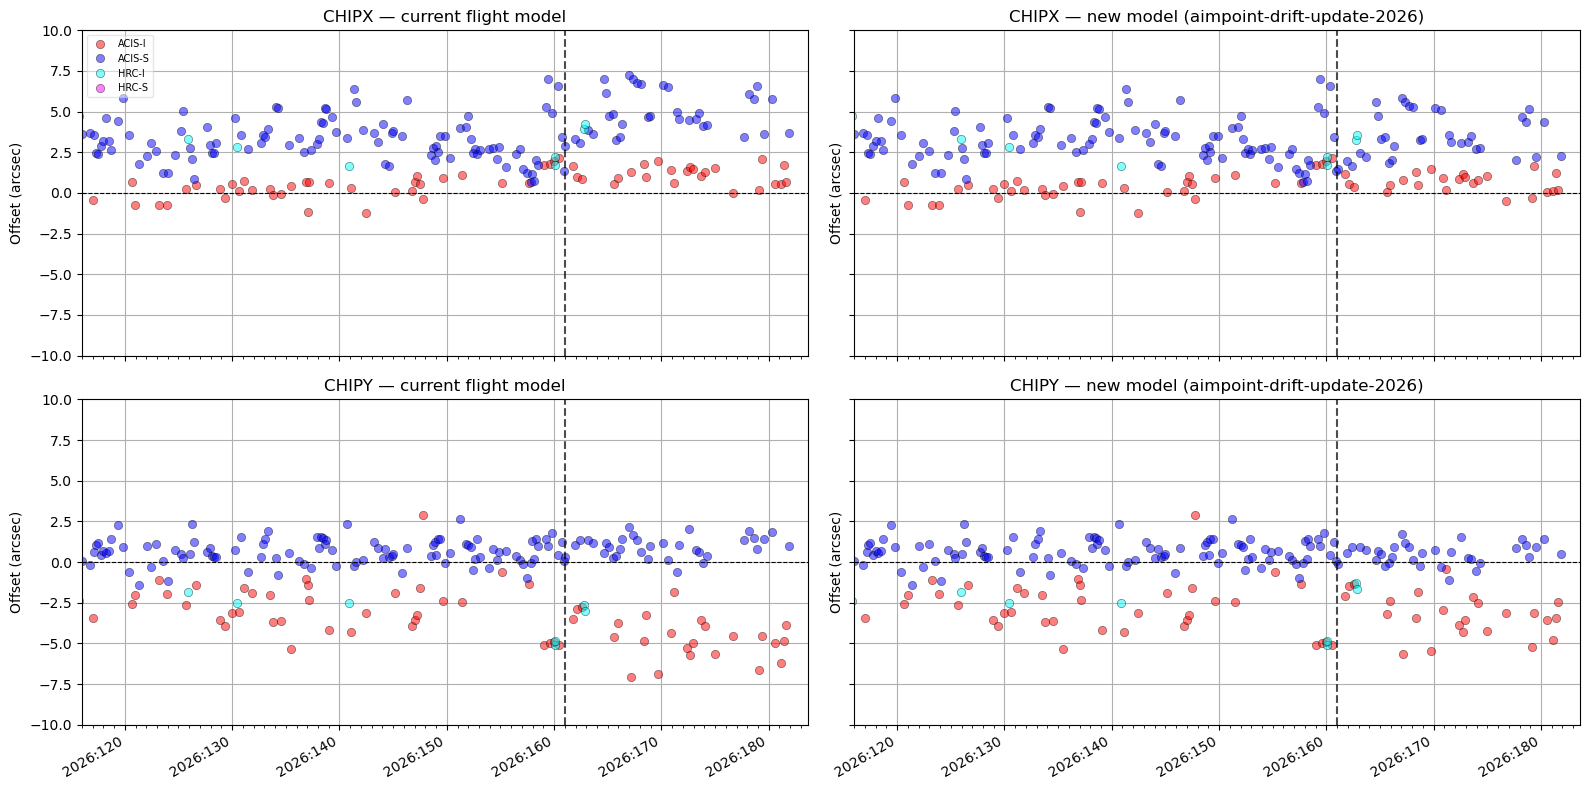

In [6]:
colors = {"ACIS-I": "red", "ACIS-S": "blue", "HRC-I": "cyan", "HRC-S": "magenta"}
model_cols = [
    ("dx_corr_flight", "dy_corr_flight"),
    ("dx_corr_new", "dy_corr_new"),
]

zoom_start = CxoTime(CxoTime(DEPLOY_JUMP_DATE).secs - 45 * 86400, format="cxcsec").plot_date
zoom_stop = CxoTime.now().plot_date

fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True, sharey="row")
axes[0, 0].set_title("CHIPX — current flight model")
axes[0, 1].set_title(f"CHIPX — new model ({os.environ['CHANDRA_MODELS_DEFAULT_VERSION']})")
axes[1, 0].set_title("CHIPY — current flight model")
axes[1, 1].set_title(f"CHIPY — new model ({os.environ['CHANDRA_MODELS_DEFAULT_VERSION']})")

for col_idx, (dx_col, dy_col) in enumerate(model_cols):
    ok_plot = np.isfinite(obs[dx_col]) & (np.abs(obs["dx"]) < 15)
    for det, c in colors.items():
        det_ok = ok_plot & (obs["detector"] == det)
        if not det_ok.sum():
            continue
        times = CxoTime(obs["mean_date"][det_ok]).secs
        for row_idx, col in enumerate([dx_col, dy_col]):
            plot_cxctime(
                times,
                obs[col][det_ok],
                marker="o",
                markerfacecolor=c,
                markeredgecolor="k",
                markeredgewidth=0.5,
                linestyle="",
                alpha=0.5,
                label=det,
                ax=axes[row_idx, col_idx],
            )

for ax in axes.flat:
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.axvline(jump_plot_date, color="k", lw=1.5, ls="--", alpha=0.7)
    ax.set_xlim(zoom_start, zoom_stop)
    ax.set_ylim(-10, 10)
    ax.set_ylabel("Offset (arcsec)")
    ax.grid()

axes[0, 0].legend(loc="upper left", fontsize="x-small", framealpha=0.5, numpoints=1)
plt.tight_layout()

## Summary statistics (post-jump)

In [7]:
post_jump = obs["mean_date"] >= DEPLOY_JUMP_DATE

print(f"Post-{DEPLOY_JUMP_DATE} observations: {post_jump.sum()}")
print()
print(f"{'detector':8s}  {'model':12s}  {'mean CHIPX':>12s}  {'std CHIPX':>10s}  {'mean CHIPY':>12s}  {'std CHIPY':>10s}  {'n':>5s}")
print("-" * 80)

for det in ["ACIS-I", "ACIS-S", "HRC-I", "HRC-S"]:
    for label, dx_col, dy_col in [
        ("flight", "dx_corr_flight", "dy_corr_flight"),
        ("new", "dx_corr_new", "dy_corr_new"),
    ]:
        ok = (
            post_jump
            & (obs["detector"] == det)
            & np.isfinite(obs[dx_col])
            & (np.abs(obs["dx"]) < 15)
        )
        n = int(ok.sum())
        if not n:
            continue
        print(
            f"{det:8s}  {label:12s}  "
            f"{np.mean(obs[dx_col][ok]):+12.3f}  "
            f"{np.std(obs[dx_col][ok]):10.3f}  "
            f"{np.mean(obs[dy_col][ok]):+12.3f}  "
            f"{np.std(obs[dy_col][ok]):10.3f}  "
            f"{n:5d}"
        )

Post-2026:161 observations: 60

detector  model           mean CHIPX   std CHIPX    mean CHIPY   std CHIPY      n
--------------------------------------------------------------------------------
ACIS-I    flight              +1.127       0.541        -4.604       1.311     24
ACIS-I    new                 +0.656       0.541        -3.194       1.311     24
ACIS-S    flight              +4.930       1.316        +0.982       0.620     34
ACIS-S    new                 +3.520       1.316        +0.512       0.620     34
HRC-I     flight              +4.071       0.157        -2.813       0.175      2
HRC-I     new                 +3.407       0.157        -1.484       0.175      2


## Using telemetered aacccdpt

Repeat the comparison using the mean telemetered `aacccdpt` over each kadi-defined
dwell instead of the `mean_t_ccd` column from the table.  Observations where kadi
has no manvr record (e.g. because the local database hasn't been updated recently)
are simply skipped and will not appear in these plots.

In [8]:
import astropy.units as u
from cheta import fetch_sci
from kadi import events
from tqdm import tqdm

# Fetch aacccdpt over the full window (degC)
t_ccd_msid = fetch_sci.Msid(
    "aacccdpt",
    start=CxoTime(LOOKBACK_START) - 5 * u.day,
    stop=CxoTime.now() + 5 * u.day,
    stat="5min",
)

obs_tel = obs.copy()
for col in ("dx_corr_flight_tel", "dy_corr_flight_tel", "dx_corr_new_tel", "dy_corr_new_tel"):
    obs_tel[col] = np.nan

for row in tqdm(obs_tel):
    det = row["detector"]
    chip_id = row["chip_id"]

    try:
        entry = drift.ASOL_TO_CHIP[(det, chip_id)]
        dwell = events.manvrs.filter(obsid=row["obsid"])[0]
    except Exception:
        continue

    dwell_tstart = CxoTime(dwell.kalman_start).secs
    dwell_tstop = (
        CxoTime(dwell.next_manvr_start).secs
        if dwell.next_manvr_start is not None
        else CxoTime.now().secs
    )
    i0, i1 = np.searchsorted(t_ccd_msid.times, [dwell_tstart, dwell_tstop])
    if i1 <= i0:
        continue
    mean_t_ccd_tel = float(np.mean(t_ccd_msid.vals[i0:i1]))

    common_tel = {
        "chip_id": chip_id,
        "chipx": row["chipx"],
        "chipy": row["chipy"],
        "time": row["mean_date"],
        "t_ccd": mean_t_ccd_tel,
    }
    offsets_flight = drift.get_aca_offsets(det, drift_pars=flight_pars, **common_tel)
    offsets_new = drift.get_aca_offsets(det, **common_tel)

    cyz = np.array(entry["cyz"])
    cyz_inv = np.linalg.inv(cyz)
    arcsec_per_pix = 0.1318 if "HRC" in det else 0.492

    for offsets, dx_col, dy_col in [
        (offsets_flight, "dx_corr_flight_tel", "dy_corr_flight_tel"),
        (offsets_new, "dx_corr_new_tel", "dy_corr_new_tel"),
    ]:
        ddy = row["aca_offset_y"] - offsets[0]
        ddz = row["aca_offset_z"] - offsets[1]
        landing_asol = (
            cyz_inv @ np.array([row["dx"], row["dy"]])
            / arcsec_per_pix
            * SIM_MM_TO_ARCSEC
        )
        total_asol = np.array([ddy, ddz]) + landing_asol
        chip_corr = cyz @ total_asol / SIM_MM_TO_ARCSEC * arcsec_per_pix
        row[dx_col] = chip_corr[0]
        row[dy_col] = chip_corr[1]

100%|██████████| 5792/5792 [01:15<00:00, 76.46it/s]


### Comparison 90 days around the jump (telemetered aacccdpt)

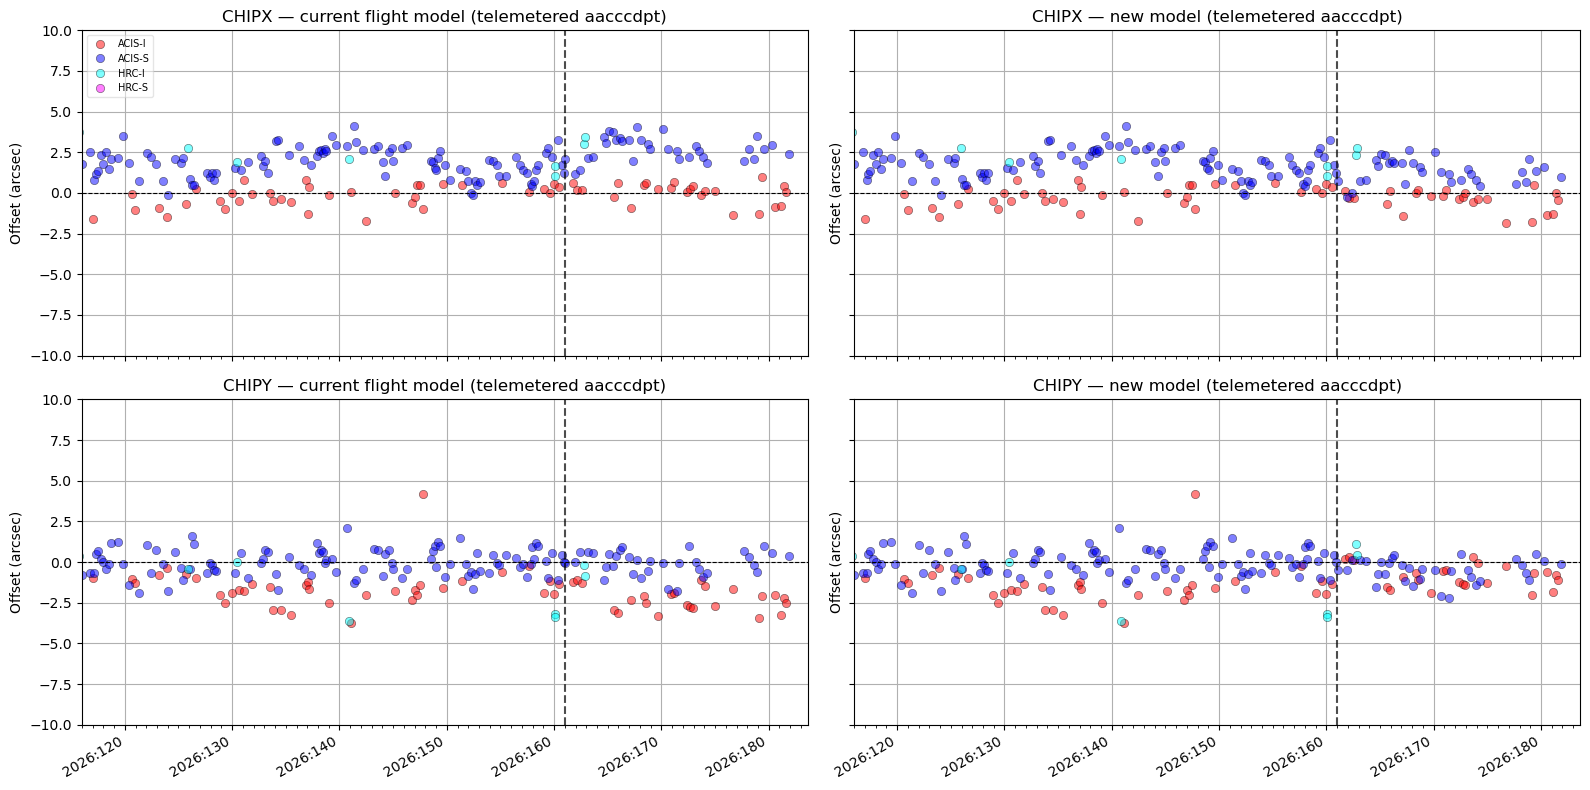

In [ ]:
model_cols_tel = [
    ("dx_corr_flight_tel", "dy_corr_flight_tel"),
    ("dx_corr_new_tel", "dy_corr_new_tel"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True, sharey="row")
axes[0, 0].set_title("CHIPX — current flight model (telemetered aacccdpt)")
axes[0, 1].set_title("CHIPX — new model (telemetered aacccdpt)")
axes[1, 0].set_title("CHIPY — current flight model (telemetered aacccdpt)")
axes[1, 1].set_title("CHIPY — new model (telemetered aacccdpt)")

for col_idx, (dx_col, dy_col) in enumerate(model_cols_tel):
    ok_plot = np.isfinite(obs_tel[dx_col]) & (np.abs(obs_tel["dx"]) < 15)
    for det, c in colors.items():
        det_ok = ok_plot & (obs_tel["detector"] == det)
        if not det_ok.sum():
            continue
        times = CxoTime(obs_tel["mean_date"][det_ok]).secs
        for row_idx, col in enumerate([dx_col, dy_col]):
            plot_cxctime(
                times,
                obs_tel[col][det_ok],
                marker="o",
                markerfacecolor=c,
                markeredgecolor="k",
                markeredgewidth=0.5,
                linestyle="",
                alpha=0.5,
                label=det,
                ax=axes[row_idx, col_idx],
            )

for ax in axes.flat:
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.axvline(jump_plot_date, color="k", lw=1.5, ls="--", alpha=0.7)
    ax.set_xlim(zoom_start, zoom_stop)
    ax.set_ylim(-10, 10)
    ax.set_ylabel("Offset (arcsec)")
    ax.grid()

axes[0, 0].legend(loc="upper left", fontsize="x-small", framealpha=0.5, numpoints=1)
plt.tight_layout()

### Summary statistics post-jump (telemetered aacccdpt)

In [10]:
post_jump_tel = obs_tel["mean_date"] >= DEPLOY_JUMP_DATE

print(f"Post-{DEPLOY_JUMP_DATE} observations: {post_jump_tel.sum()}")
print()
print(f"{'detector':8s}  {'model':12s}  {'mean CHIPX':>12s}  {'std CHIPX':>10s}  {'mean CHIPY':>12s}  {'std CHIPY':>10s}  {'n':>5s}")
print("-" * 80)

for det in ["ACIS-I", "ACIS-S", "HRC-I", "HRC-S"]:
    for label, dx_col, dy_col in [
        ("flight", "dx_corr_flight_tel", "dy_corr_flight_tel"),
        ("new", "dx_corr_new_tel", "dy_corr_new_tel"),
    ]:
        ok = (
            post_jump_tel
            & (obs_tel["detector"] == det)
            & np.isfinite(obs_tel[dx_col])
            & (np.abs(obs_tel["dx"]) < 15)
        )
        n = int(ok.sum())
        if not n:
            continue
        print(
            f"{det:8s}  {label:12s}  "
            f"{np.mean(obs_tel[dx_col][ok]):+12.3f}  "
            f"{np.std(obs_tel[dx_col][ok]):10.3f}  "
            f"{np.mean(obs_tel[dy_col][ok]):+12.3f}  "
            f"{np.std(obs_tel[dy_col][ok]):10.3f}  "
            f"{n:5d}"
        )

Post-2026:161 observations: 60

detector  model           mean CHIPX   std CHIPX    mean CHIPY   std CHIPY      n
--------------------------------------------------------------------------------
ACIS-I    flight              +0.032       0.624        -2.264       0.701     24
ACIS-I    new                 -0.440       0.624        -0.853       0.701     24
ACIS-S    flight              +2.725       0.705        -0.049       0.699     34
ACIS-S    new                 +1.314       0.705        -0.519       0.699     34
HRC-I     flight              +3.243       0.217        -0.530       0.341      2
HRC-I     new                 +2.579       0.217        +0.799       0.341      2
